In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import time

In [68]:
data = pd.read_csv(r"data/train_test.csv")
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [69]:
validation = pd.read_csv("data/validation.csv")
validation.head()


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [70]:
dec_chart = pd.read_csv("data/december_chart_inputs.csv")
dec_chart.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,828.873459
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,833.491098
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,836.405957
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,837.393192
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,836.961274


In [71]:
comparasion = set(data.columns) - set(dec_chart.columns)
comparasion

{'delivery_lat',
 'delivery_lon',
 'load_id',
 'market_index',
 'pickup_lat',
 'pickup_lon',
 'posted_rate',
 'quote_signal'}

validation has every column

coordinates, market_index, quote_signal
 are not in dec chart


In [72]:
rate_per_mile = (data["posted_rate"]/data["distance"])
data["rate_per_mile"] = rate_per_mile
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rate_per_mile
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,2.352935
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,2.424135
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1.862513
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,1.892770
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,2.547112


add a new column named rate per mile because it remove distance so you can compare loads fairly

a quick check on december chart set



In [73]:
dec_chart.isna().sum()

pickup            0
delivery          0
distance          0
equipment         0
weight            0
date              0
predicted_rate    0
dtype: int64

In [74]:
dec_chart

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,828.873459
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,833.491098
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,836.405957
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,837.393192
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,836.961274
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,833.616716
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,827.997640
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,828.873459
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,833.491098
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,836.405957


FINDING :

december chart is one load priced on 31 different days. all rows share the same features only the date changes. so the chart test if the model learned how rates move over time because a model that ignore the date would produce a flat line.

now i will check whether rate per mile actually varies by date in training data and how (weekday , month , holidays)


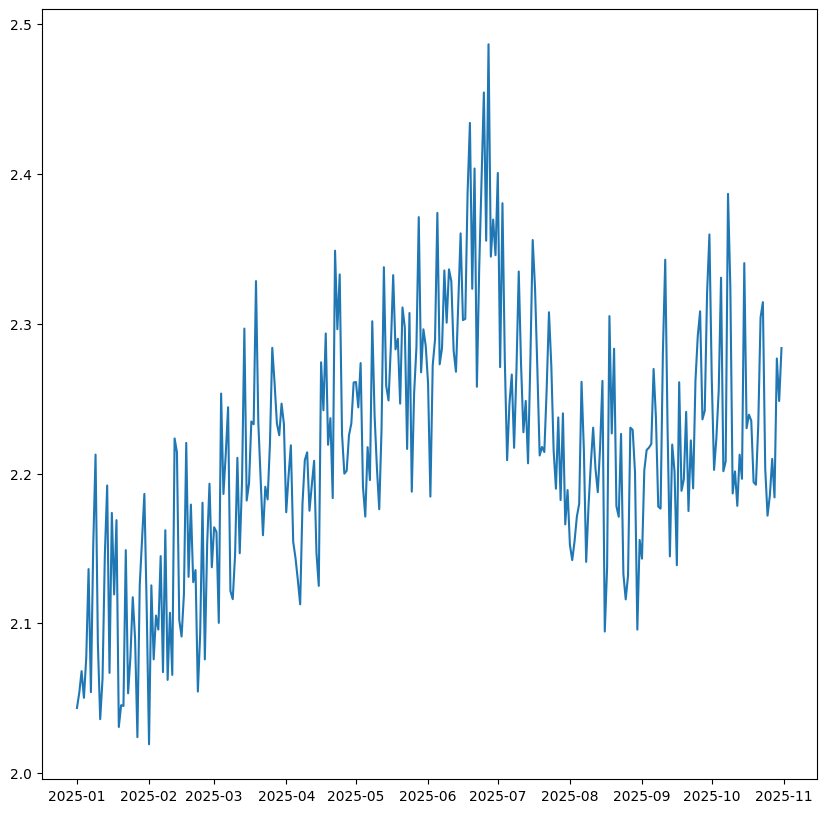

In [75]:
data['date'] = pd.to_datetime(data['date'])
gr = data['rate_per_mile'].groupby(data['date']).mean()
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(gr.index , gr)
plt.show()


In [76]:
gr_month = data['date'].dt.month
gr_month_mean = data['rate_per_mile'].groupby(gr_month).mean()
print((gr_month_mean.max()-gr_month_mean.min())/gr_month_mean.min()*100)

11.058978362591109


In [77]:
gr_month_mean

date
1     2.100221
2     2.122885
3     2.206132
4     2.210309
5     2.260106
6     2.332484
7     2.255952
8     2.188584
9     2.229725
10    2.239763
Name: rate_per_mile, dtype: float64

FINDING :

rates are seasonal .2.1 in January to 2.33 at the peak

11% swing

lowest at the start of the year and it peaks at june which indicate the summer time and average for the rest of year .


but there is a zigzag in each few days which is a sign that the days also have a role in this changes which i will investigate next .

In [78]:
days = data['date'].dt.dayofweek
days_mean = data['rate_per_mile'].groupby(days).mean()
days_mean

date
0    2.196373
1    2.213440
2    2.248383
3    2.244592
4    2.214910
5    2.195747
6    2.192251
Name: rate_per_mile, dtype: float64

In [79]:
print((days_mean.max()-days_mean.min())/days_mean.min()*100)

2.5604538305404274


<BarContainer object of 7 artists>

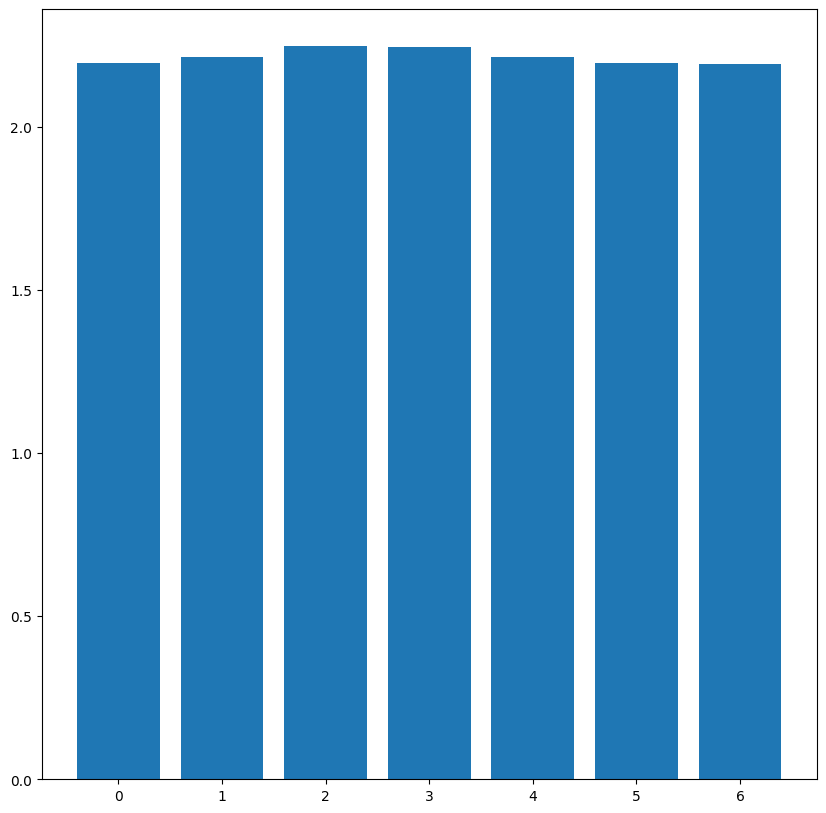

In [80]:
fig , ax = plt.subplots(figsize=(10,10))
ax.bar(days_mean.index, days_mean)

highest rate in the days of week was wednesday and thursday with 2.24 vs 2.19 around the weekend
about 2.5% swing vs 11% for months

midweek is the pricier shipping time but days of week has much less effect on rate than months

In [81]:
print(data['date'].min(), data['date'].max())
print(validation['date'].min(), validation['date'].max())

2025-01-01 00:00:00 2025-10-31 00:00:00
2025-11-01 2025-12-31


training covers january to october and validation covers november and december.

tree models cant predict outside the range they were trained on, a load in december lands on the same branch as october. so the model cant learn a december pattern from this data, and september and october are the most valuable months because they are the closest to what we predict. the final model has to be retrained on all the data including them

0.034165098295577574
0.08347811751487433


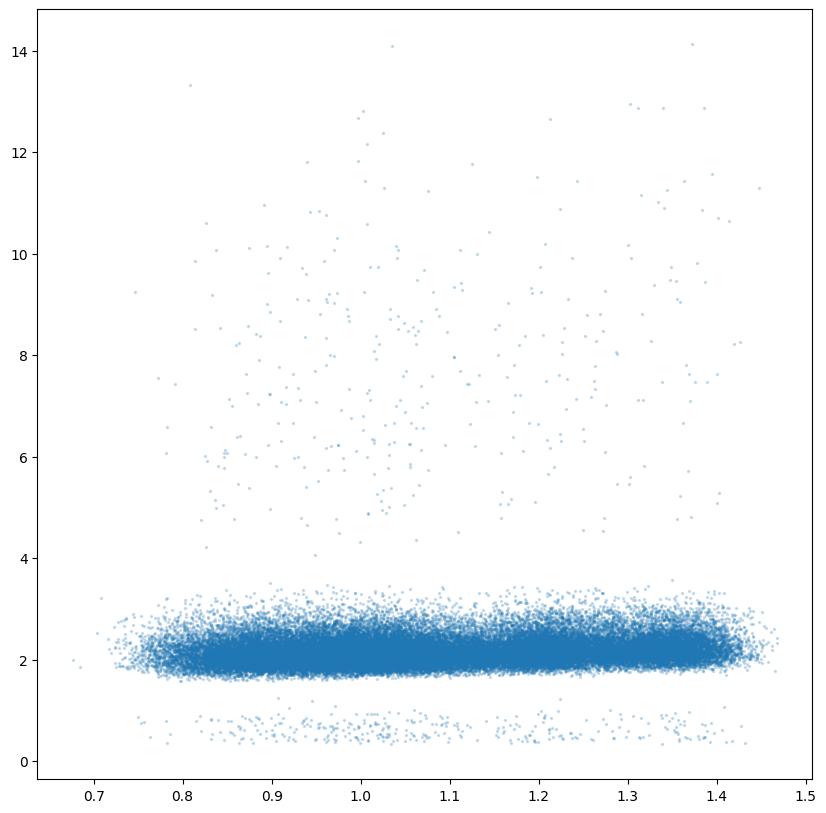

In [82]:
mi = data["market_index"].corr(data["posted_rate"])
print(mi)
mir = data["market_index"].corr(data["rate_per_mile"])
print(mir)
fig , ax = plt.subplots(figsize=(10,10))
ax.scatter(data["market_index"], data["rate_per_mile"],s=2 ,alpha=0.2)
plt.show()


correlation numbers: 0.03 with the raw rate, 0.08 per mile

the plot show a flat band at 2 to 3 ,an expensive group at 5 to 14 , and a cheap strip around $0.5

In [83]:
high = data[data["rate_per_mile"] > 4]
low = data[data["rate_per_mile"] < 4]
high["distance"].describe()


count     340.000000
mean     1076.793824
std       704.207601
min        70.000000
25%       534.125000
50%       928.600000
75%      1506.325000
max      3183.800000
Name: distance, dtype: float64

In [84]:
low["distance"].describe()

count    47660.000000
mean      1136.278000
std        728.725196
min         70.000000
25%        550.600000
50%        953.400000
75%       1646.700000
max       3439.800000
Name: distance, dtype: float64

hypothesis: expensive loads are short trips.

Rejected: median distance 929 vs 953

check how much is equipments have to do with the price



In [85]:
equip_count = high["equipment"].value_counts(normalize=True)
equip_count

equipment
Dry Van    0.579412
Reefer     0.235294
Flatbed    0.185294
Name: proportion, dtype: float64

In [86]:
equip_count = low["equipment"].value_counts(normalize=True)
equip_count

equipment
Dry Van    0.566618
Reefer     0.251049
Flatbed    0.182333
Name: proportion, dtype: float64

it doesnt : dry van 58% vs 57%, reefer 24% vs 25%, flatbed 19% vs 18%



now we check the cheap group where rate per mile < 1

In [87]:
low_rate = data[data["rate_per_mile"] < 1]
low_rate['distance'].describe()


count     329.000000
mean     1086.034954
std       725.241376
min        93.900000
25%       546.700000
50%       855.000000
75%      1552.600000
max      2994.600000
Name: distance, dtype: float64

In [88]:
low_rate['posted_rate'].describe()

count     329.000000
mean      639.153556
std       417.350256
min        57.220000
25%       328.370000
50%       551.310000
75%       854.190000
max      2134.820000
Name: posted_rate, dtype: float64

FINDING : the cheap group mirror the expensive group. 329 loads are priced below 1 per mile (mean 0.62, versus about 2.20 normally). Their distances look normal (median 855 miles vs 953), so the price is the unusual part at roughly a quarter of a normal rate.

together with the 340 expensive loads, that is about 670 loads whose price does not match their features.



now to check whether the expensive loads cluster in certain months

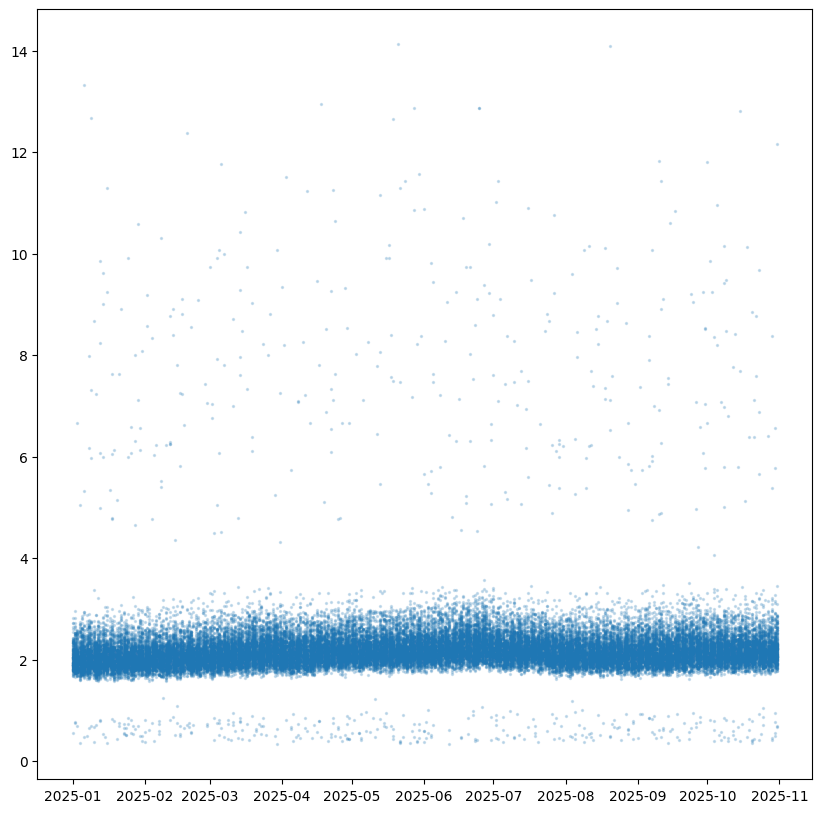

In [89]:
fig , ax = plt.subplots(figsize=(10,10))
ax.scatter(data['date'], data['rate_per_mile'],s=2, alpha=0.2)
plt.show()

FINDING :

the unusual prices are spread evenly across the year. Both the expensive and the cheap loads appear in every month, with no clustering in any period.

So far, nothing separates the unusual loads from normal ones :

Distance: same range and median.

Equipment: same shares.

Weight: spread across the normal range.

Date: spread evenly across the year.

This supports treating them as unpredictable noise


now check location



In [90]:
high_pickup = high["pickup"].value_counts(normalize=True)
low_pickup = low["pickup"].value_counts(normalize=True)
high_pickup

pickup
Mobile        0.032353
Montgomery    0.032353
Lexington     0.032353
Hartford      0.026471
Phoenix       0.026471
                ...   
Detroit       0.005882
Savannah      0.005882
Lubbock       0.002941
St. Louis     0.002941
Madison       0.002941
Name: proportion, Length: 62, dtype: float64

In [91]:
low_pickup

pickup
Oklahoma City    0.025913
Lexington        0.025136
Bakersfield      0.024906
Fort Wayne       0.024423
Hartford         0.023940
                   ...   
Detroit          0.007029
Washington       0.006945
St. Louis        0.006651
Las Vegas        0.005770
Dallas           0.005665
Name: proportion, Length: 64, dtype: float64

In [92]:
compare = pd.DataFrame({"high": high_pickup, "normal": low_pickup})
compare.head(10)


,high,normal
pickup,,
Albany,0.017647,0.016890
Albuquerque,0.011765,0.012107
Amarillo,0.017647,0.017415
Atlanta,0.017647,0.021465
Austin,0.008824,0.008183
Bakersfield,0.017647,0.024906
Baltimore,0.005882,0.009987
Baton Rouge,0.023529,0.023227
Birmingham,NaN,0.007637


In [93]:
compare["diff"] = compare["high"] - compare["normal"]
compare.sort_values("diff")
compare.fillna(0)

,high,normal,diff
pickup,,,
Albany,0.017647,0.016890,0.000757
Albuquerque,0.011765,0.012107,-0.000342
Amarillo,0.017647,0.017415,0.000232
Atlanta,0.017647,0.021465,-0.003817
Austin,0.008824,0.008183,0.000641
...,...,...,...
Tampa,0.008824,0.011309,-0.002486
Toledo,0.017647,0.015506,0.002141
Tucson,0.026471,0.019618,0.006852


In [94]:
high_delivery = high["delivery"].value_counts(normalize=True)
low_delivery = low["delivery"].value_counts(normalize=True)

compare_delivery = pd.DataFrame({"high": high_delivery, "normal": low_delivery}).fillna(0)
compare_delivery["diff"] = compare_delivery["high"] - compare_delivery["normal"]
compare_delivery.sort_values("diff")

,high,normal,diff
delivery,,,
Los Angeles,0.002941,0.020017,-0.017076
El Paso,0.002941,0.016114,-0.013173
Montgomery,0.005882,0.018905,-0.013022
Kansas City,0.008824,0.020499,-0.011676
San Francisco,0.000000,0.009799,-0.009799
...,...,...,...
Savannah,0.023529,0.010911,0.012619
Memphis,0.032353,0.018905,0.013448
Baton Rouge,0.038235,0.024213,0.014022


routes: no pickup or delivery city is strongly over represented. The largest gap is Baltimore with about 10 loads, consistent with chance.



THE FULL RESULT ON OUTLIERS :

the odd prices arent explained by distance, equipment, weight, date, pickup city or delivery city. Thats very strong support for dropping them from training



i will remove them from training only so they do not pull predictions for normal loads up or down

keep them in the test because the real validation set will contain loads like these and removing them would make the score look better than it really is.

now weights


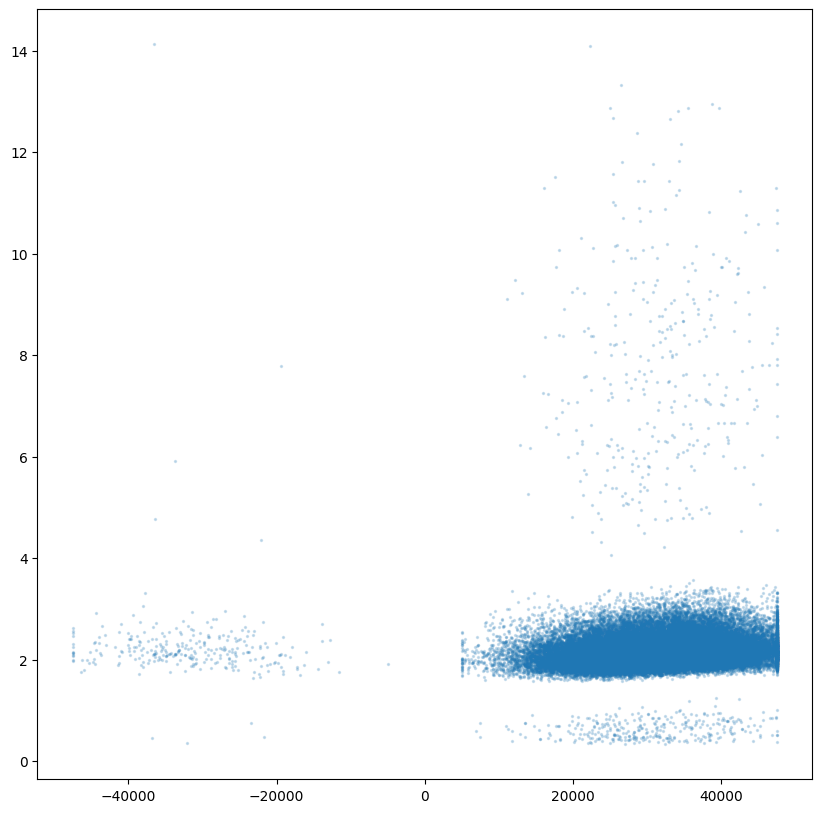

In [95]:

fig , ax = plt.subplots(figsize=(10,10))
ax.scatter(data["weight"], data["rate_per_mile"],s=2 ,alpha=0.2)
plt.show()

the clipping at 5,000 and 47,500

the outliers at left are probably negative weights which i will check now

In [96]:
n_weights = data[data["weight"]<0]
n_weights["weight"].describe()

count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64

In [97]:
p_weights = data[data["weight"]>0]
p_weights["weight"].describe()

count    47408.000000
mean     31415.358674
std       7994.902979
min       5000.000000
25%      25922.000000
50%      31493.500000
75%      37063.000000
max      47500.000000
Name: weight, dtype: float64

In [98]:
data["weight"].isna().sum()

np.int64(300)

we have 292 negative weight , 300 null
distribution mirrors the positive weights (same mean, median and range), which suggests a random sign error rather than different loads .

i will use .abs() to make all values positive


In [99]:
data["weight"] = data["weight"].abs()
data["weight"].describe()

count    47700.000000
mean     31417.249245
std       7996.515399
min       5000.000000
25%      25922.000000
50%      31496.000000
75%      37063.250000
max      47500.000000
Name: weight, dtype: float64

now we have 300 null weight value which i will handle at modeling stage

i will check for the rest of negative weights in validation set and the rest of nulls in validation and training set


In [100]:
val_n_weights = validation[validation["weight"]<0]
val_n_weights["weight"].describe()

count      145.000000
mean    -31681.820690
std       8094.232211
min     -47500.000000
25%     -37679.000000
50%     -32517.000000
75%     -26289.000000
max      -8229.000000
Name: weight, dtype: float64

In [101]:
validation["weight"] = validation["weight"].abs()
validation["weight"].describe()

count    11835.000000
mean     31282.954626
std       7987.942191
min       5000.000000
25%      25753.500000
50%      31332.000000
75%      36939.000000
max      47500.000000
Name: weight, dtype: float64

validation has 145 negative weights with the same mirror pattern so i fixed them the same way with abs()

In [102]:
validation.isna().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64

In [103]:
data.isna().sum()

load_id            0
pickup             0
delivery           0
pickup_lat         0
pickup_lon         0
delivery_lat       0
delivery_lon       0
distance           0
equipment          0
weight           300
date               0
market_index     374
quote_signal       0
posted_rate        0
rate_per_mile      0
dtype: int64

market_index and weight have missing values in both training and validation sets



now check quote_signal correlation with rate_per_mile

In [104]:
qs = data['quote_signal'].corr(data['rate_per_mile'])
qs

np.float64(0.049342214089282244)

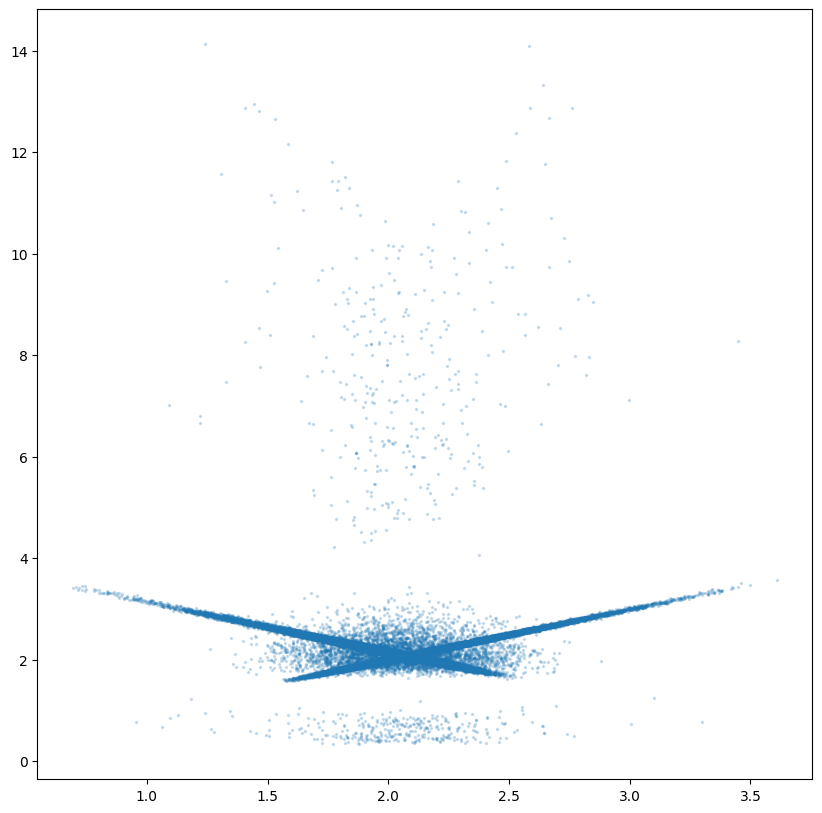

In [105]:
fig , ax = plt.subplots(figsize=(10,10))
ax = plt.scatter(data['quote_signal'], data['rate_per_mile'],s=2, alpha=0.2)
plt.show()

FINDING :

quote_signal is "target leakage"

Its correlation with rate per mile is only 0.05 but the scatter plot shows an X shape: two straight lines plus a random cloud.
rising line : for these loads quote_signal equals the rate per mile.

falling line : a mirrored version of the same relationship.

cloud : no relation at all

the 2 lines cancel out which is why the correlation look near 0. the correlation alone would have hidden this.

the quote_signal appear to be calculated from the price itself so it will not exist when real load need a price, it is also missing from the december file.

it will be dropped


ABOUT THE MARKET_INDEX :

weak relationship: correlation 0.03 with the rate, and 0.08 with rate per mile.
the scatter plot shows a flat band with no hidden shape, unlike quote_signal.
it is completely missing from the December chart file.
it also has missing values: 374 in training and 249 in validation.

keeping it would require a second model just for December, or filling in all 31 December values, which is not worth it for a feature that shows no signal.



now we check for duplicates


In [106]:
data["load_id"].duplicated().sum()

np.int64(0)

In [107]:
data.drop(columns=["load_id"]).duplicated().sum()

np.int64(0)

no duplicate in the training data

before dropping anything

SPLIT APPROACH :

im gonna split the data based on time. training on january to august and testing on september to october. because the real task is predicting two unseen future months. a random split would let the model peek at the future and give a falsely optimistic score.


In [108]:
train = data[data['date']<'2025-09-01']
test = data[data['date']>='2025-09-01']
print(len(train)+len(test))

48000


now we need a baseline before training any model

In [109]:
base = train['rate_per_mile'].median()
base

np.float64(2.1411506730351713)

In [110]:
pred_base = base * test['distance']
from sklearn.metrics import mean_absolute_error
mean_absolute_error(test['posted_rate'],pred_base)

256.9529387982172

BASELINE:

median rate per mile from the training period (2.14) times distance. test MAE: 257. Any model must beat this.

before dropping i have to check whether every city have 1 set of coordinates because december chart doesnt have them

In [111]:
data.groupby("pickup")["pickup_lat"].nunique().max()

np.int64(1)

In [112]:
data.groupby("pickup")["pickup_lon"].nunique().max()

np.int64(1)

In [113]:
data.groupby("delivery")["delivery_lat"].nunique().max()

np.int64(1)

In [114]:
data.groupby("delivery")["delivery_lon"].nunique().max()

np.int64(1)

every city has exactly 1 set of coordinates, so the coordinates are just the city name as numbers.

i keep the coordinates and drop the names because a tree can learn geography from numbers (nearby cities get treated the same) and its 4 columns instead of about 128 one hot columns. for december i look them up from the training data

now the cleaning function

In [115]:
df = data.copy()


In [116]:
def cleaning (dataframe):
    dataframe = dataframe.copy()
    dataframe['weight']= dataframe['weight'].abs()
    dataframe['date'] = pd.to_datetime(dataframe['date'])
    dataframe['month'] = dataframe['date'].dt.month
    dataframe['day_of_week'] = dataframe['date'].dt.dayofweek
    return dataframe


the same fixes for every file: abs on weight, date to datetime, and month and day of week as new columns

In [117]:
train_raw = pd.read_csv("data/train_test.csv")
val_raw = pd.read_csv("data/validation.csv")
dec_raw = pd.read_csv("data/december_chart_inputs.csv")

train_clean = cleaning(train_raw)
val_clean = cleaning(val_raw)
dec_clean = cleaning(dec_raw)

print(train_clean["weight"].min(), val_clean["weight"].min(), dec_clean["weight"].min())
print(train_clean[["date", "month", "day_of_week"]].head())

5000.0 5000.0 32000
        date  month  day_of_week
0 2025-01-01      1            2
1 2025-01-01      1            2
2 2025-01-01      1            2
3 2025-01-01      1            2
4 2025-01-01      1            2


loaded the raw files again to test the function from scratch. min weight is 5000 in train and validation so no negatives left

turning the data into a model inputs

In [118]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore')
encoder.fit(train_clean[["equipment"]])
encoder.categories_

[array(['Dry Van', 'Flatbed', 'Reefer'], dtype=object)]

december only has dry van so get_dummies would make 1 column instead of 3 and break the model. the encoder is fitted on training data and always gives the same 3 columns for any file

december chart dont have coordinates so im gonna get them from training data

even though december chart have only 1 location for pickup and 1 for delivery i will build a lookup table for every city, so it would still work if the december file used other cities

In [119]:
pickup_coords = train_clean.drop_duplicates("pickup").set_index("pickup")[["pickup_lat", "pickup_lon"]]
delivery_coords = train_clean.drop_duplicates("delivery").set_index("delivery")[["delivery_lat", "delivery_lon"]]

dec_clean["pickup_lat"] = dec_clean["pickup"].map(pickup_coords["pickup_lat"])
dec_clean["pickup_lon"] = dec_clean["pickup"].map(pickup_coords["pickup_lon"])
dec_clean["delivery_lat"] = dec_clean["delivery"].map(delivery_coords["delivery_lat"])
dec_clean["delivery_lon"] = dec_clean["delivery"].map(delivery_coords["delivery_lon"])

dec_clean[["pickup", "pickup_lat", "pickup_lon", "delivery", "delivery_lat", "delivery_lon"]].head(3)

,pickup,pickup_lat,pickup_lon,delivery,delivery_lat,delivery_lon
0,Lexington,36.99152,-84.99876,Fort Wayne,41.31561,-85.36206
1,Lexington,36.99152,-84.99876,Fort Wayne,41.31561,-85.36206
2,Lexington,36.99152,-84.99876,Fort Wayne,41.31561,-85.36206


now features drop


In [120]:
train_clean.columns

Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'posted_rate', 'month',
       'day_of_week'],
      dtype='object')

In [121]:
DROP = ["posted_rate", "quote_signal", "market_index", "load_id",
        "pickup", "delivery", "equipment", "date"]

FEATURES = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon",
    "distance", "weight",
    "month", "day_of_week",
]

the model uses 8 features: location (4 coordinates), size (distance and weight) and time (month and day of week).

the rest is the target, the leakage (quote_signal), market_index, the id, and text columns that are replaced by numbers. i use a keep list instead of a drop list because every file has different columns

In [122]:
tr = train_clean[train_clean["date"] < "2025-09-01"].copy()
te = train_clean[train_clean["date"] >= "2025-09-01"].copy()
print("before:", len(tr), len(te))

tr["rate_per_mile"] = tr["posted_rate"] / tr["distance"]
tr = tr[(tr["rate_per_mile"] > 1) & (tr["rate_per_mile"] < 4)]
print("after:", len(tr), len(te))

before: 38477 9523
after: 37951 9523


split the cleaned data again by date and removed the odd loads (rate per mile under 1 or over 4) from the training part only. 526 loads removed, the test stays untouched

In [123]:
weight_median = tr["weight"].median()

def make_X(df):
    X = df[FEATURES].copy()
    X["weight"] = X["weight"].fillna(weight_median)
    equip = encoder.transform(df[["equipment"]]).toarray()
    for i, name in enumerate(encoder.categories_[0]):
        X["equip_" + name] = equip[:, i]
    return X

X_tr, y_tr = make_X(tr), tr["posted_rate"]
X_te, y_te = make_X(te), te["posted_rate"]

print(X_tr.shape, X_te.shape)
print(X_tr.isna().sum().sum())
X_tr.head(3)

(37951, 11) (9523, 11)
0


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,month,day_of_week,equip_Dry Van,equip_Flatbed,equip_Reefer
0,38.09122,-76.78906,38.16908,-72.74564,274.3,30658.0,1,2,1.0,0.0,0.0
1,38.09122,-76.78906,39.22317,-72.96710,280.5,17555.0,1,2,0.0,0.0,1.0
2,39.22317,-72.96710,44.30296,-87.52871,967.8,31721.0,1,2,1.0,0.0,0.0


missing weights are filled with the training median and the equipment is added as 3 columns from the encoder. 11 columns and no missing values

In [124]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(random_state=42,n_jobs=-1)
model.fit(X_tr, y_tr)
preds = model.predict(X_te)
print(model.score(X_te, y_te),
mean_absolute_error(y_te, preds))



0.8284477765152751 106.45246001260108


In [125]:
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_tr, y_tr)
preds_lgbm = lgbm.predict(X_te)
print(lgbm.score(X_te, y_te), mean_absolute_error(y_te, preds_lgbm))

0.8276835392350661 107.61013446607228


In [126]:
from xgboost import XGBRegressor

xgb = XGBRegressor(random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr)
preds_xgb = xgb.predict(X_te)
print(xgb.score(X_te, y_te), mean_absolute_error(y_te, preds_xgb))

0.8275044215765499 109.90187476292235


results on september and october:

baseline 257

random forest 106.45 (r2 0.83)

lightgbm 107.61 (r2 0.83)

xgboost 109.90 (r2 0.83)

all three cut the baseline error by more than half

the models have nearly similar result

im gonna try to check average rate per mile by each lane to see if i find useful informations for the model

In [127]:
tr['lane']= tr['pickup']+' to '+tr['delivery']
tr['lane'].value_counts().median()

np.float64(8.0)

3997 lanes and a typical lane has only 8 loads, some have just 1. a lane average from a few loads is mostly luck, and it includes the load own price which is target leakage.

so i use TargetEncoder: it computes each training load lane value without its own price (out of fold) and pulls small lanes toward the overall average (smoothing)

In [128]:
(tr["lane"] == "Lexington to Fort Wayne").sum()


np.int64(26)

the december lane has 26 loads so its lane value is reliable

In [129]:
from sklearn.preprocessing import TargetEncoder
lane_enc = TargetEncoder(target_type="continuous",random_state=42)
tr["lane_rpm"] = lane_enc.fit_transform(tr[["lane"]], tr["rate_per_mile"])[:, 0]
te["lane"] = te["pickup"] + " to " + te["delivery"]
te["lane_rpm"] = lane_enc.transform(te[["lane"]])[:, 0]

In [130]:
FEATURES_LANE = FEATURES + ["lane_rpm"]

def make_X(df, feats):
    X = df[feats].copy()
    X["weight"] = X["weight"].fillna(weight_median)
    equip = encoder.transform(df[["equipment"]]).toarray()
    for i, name in enumerate(encoder.categories_[0]):
        X["equip_" + name] = equip[:, i]
    return X

X_tr_lane = make_X(tr, FEATURES_LANE)
X_te_lane = make_X(te, FEATURES_LANE)

model_lane = RandomForestRegressor(random_state=42, n_jobs=-1)
model_lane.fit(X_tr_lane, y_tr)
preds_lane = model_lane.predict(X_te_lane)
print(model_lane.score(X_te_lane, y_te), mean_absolute_error(y_te, preds_lane))

0.828637794593557 105.66538284154153


tested a leakage safe lane encoding (out_of_fold target encoding with smoothing). improvement: 0.8. The coordinates already captured most of the route effect

i will try to make the model learns rate per mile instead, distance is already divided out. the model can focus on what makes one mile cheaper or pricier than another: route, season, equipment.

In [131]:
from sklearn.metrics import r2_score
model_rpm = RandomForestRegressor(random_state=42, n_jobs=-1)
model_rpm.fit(X_tr_lane, tr["rate_per_mile"])

rpm_pred = model_rpm.predict(X_te_lane)
preds_rpm = rpm_pred * te["distance"]

print(r2_score(y_te, preds_rpm), mean_absolute_error(y_te, preds_rpm))

0.8276927647590879 107.55678993611119


107.56 vs 105.67, worse so i rejected it. a small mistake in rate per mile gets multiplied by distance so long trips get big errors

In [132]:
lgbm_lane = LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1)
lgbm_lane.fit(X_tr_lane, y_tr)
preds_lgbm_lane = lgbm_lane.predict(X_te_lane)

preds_avg = (preds_lane + preds_lgbm_lane) / 2

print("LightGBM + lane:", mean_absolute_error(y_te, preds_lgbm_lane))
print("Average:        ", mean_absolute_error(y_te, preds_avg), r2_score(y_te, preds_avg))

LightGBM + lane: 107.84055292069694
Average:         102.45012123420761 0.8285069169944319


average of random forest and lightgbm: 102.45, the best result. lightgbm alone got worse with the lane but the average beat both because they make different mistakes and averaging cancels part of them

baseline 257

random forest 106.45

random forest + lane 105.67

lightgbm + lane 107.84

rate per mile target 107.56 (rejected)

average of rf and lightgbm with lane 102.45

final model: retrain on everything from january to october, including september and october because they are the closest months to november and december. the weight median and the lane encoder are refit on all the data too, then i predict validation and december and average the two models

In [133]:
full = train_clean.copy()
full["rate_per_mile"] = full["posted_rate"] / full["distance"]
full = full[(full["rate_per_mile"] > 1) & (full["rate_per_mile"] < 4)]

weight_median = full["weight"].median()
full["lane"] = full["pickup"] + " to " + full["delivery"]
lane_enc_final = TargetEncoder(target_type="continuous", random_state=42)
full["lane_rpm"] = lane_enc_final.fit_transform(full[["lane"]], full["rate_per_mile"])[:, 0]

for df in [val_clean, dec_clean]:
    df["lane"] = df["pickup"] + " to " + df["delivery"]
    df["lane_rpm"] = lane_enc_final.transform(df[["lane"]])[:, 0]

X_full, y_full = make_X(full, FEATURES_LANE), full["posted_rate"]
rf_final = RandomForestRegressor(random_state=42, n_jobs=-1).fit(X_full, y_full)
lgbm_final = LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1).fit(X_full, y_full)

def predict_avg(df):
    X = make_X(df, FEATURES_LANE)
    return (rf_final.predict(X) + lgbm_final.predict(X)) / 2

val_preds = pd.Series(predict_avg(val_clean), index=val_clean["load_id"])
template = pd.read_csv("data/validation_predictions_template.csv")
template["predicted_rate"] = template["load_id"].map(val_preds)
assert len(template) == 12_000
assert template["predicted_rate"].notna().all() and (template["predicted_rate"] > 0).all()
template[["load_id", "predicted_rate"]].to_csv("validation_predictions.csv", index=False)

dec_out = dec_raw.copy()
dec_out["predicted_rate"] = predict_avg(dec_clean)
dec_out.to_csv("data/december_chart_inputs.csv", index=False)

print(template.head(), dec_out[["date", "predicted_rate"]].head(), sep="\n\n")

     load_id  predicted_rate
0  TE-000001      860.815064
1  TE-000002     5105.186244
2  TE-000003     5217.034394
3  TE-000004     4059.226473
4  TE-000005     1903.101312

         date  predicted_rate
0  2025-12-01      828.873459
1  2025-12-02      833.491098
2  2025-12-03      836.405957
3  2025-12-04      837.393192
4  2025-12-05      836.961274


score.py validated both files (12,000 predictions and 31 december predictions) and made the chart.

the december chart is a weekly wave: wednesday and thursday highest, weekend lowest, and christmas looks like any other thursday. this is expected, the training data has no december or holidays so the model treats december like october. the swing is only about 828 to 837 (about 1%)